# ATLAS Higgs Boson Machine Learning Challenge ~~2014~~ 2026

## Dataset overview:

|  Column                     | Dtype | UNDEF | Description |
|-----------------------------|-------|-------| ------------|
|  EventId                    | int64   |-| An unique integer identifier of the event.|  
|  DER_mass_MMC               | float64 |-| The estimated mass $m_H$ of the Higgs boson candidate, obtained through a probabilistic phase space integration.
|  DER_mass_transverse_met_lep | float64 |-|   The transverse mass between the missing transverse energy and the lepton.
|  DER_mass_vis               | float64 |-| The invariant mass of the hadronic tau and the lepton.
|  DER_pt_h                   | float64 |-| The modulus of the vector sum of the transverse momentum of the hadronic tau, the lepton and the missing transverse energy vector.
|  DER_deltaeta_jet_jet       | float64 | PRI_jet_num <= 1 | The absolute value of the pseudorapidity separation between the two jets (undefined if PRI_jet_num ≤ 1).
|  DER_mass_jet_jet           | float64 | PRI_jet_num <= 1 | The invariant mass of the two jets (undefined if PRI_jet_num ≤ 1).
|  DER_prodeta_jet_jet        | float64 | PRI_jet_num <= 1 | The product of the pseudorapidities of the two jets (undefined if PRI_jet_num ≤ 1).
|  DER_deltar_tau_lep         | float64 |-| The R separation between the hadronic tau and the lepton.
|  DER_pt_tot                 | float64 |-| The modulus of the vector sum of the missing transverse momenta and the transverse momenta of the hadronic tau, the lepton, the leading jet (if PRI_jet_num ≥) and the subleading jet (if PRI jet num = 2) (but not of any additional jets).
|  DER_sum_pt                 | float64 |-| The sum of the moduli of the transverse momenta of the hadronic tau, the lepton, the leading jet (if PRI jet num ≥ 1) and the subleading jet (if PRI jet num = 2) and the other jets (if PRI jet num = 3).
|  DER_pt_ratio_lep_tau       | float64 |-| The ratio of the transverse momenta of the lepton and the hadronic tau.
|  DER_met_phi_centrality     | float64 |-| The centrality of the azimuthal angle of the missing transverse energy vector w.r.t. the hadronic tau and the lepton.
|  DER_lep_eta_centrality     | float64 |PRI_jet_num <= 1 | The centrality of the pseudorapidity of the lepton w.r.t. the two jets (undefined if PRI_jet_num ≤ 1).
|  PRI_tau_pt                 | float64 |-| The transverse momentum $\sqrt{p^2_x+p^2_y}$ of the hadronic tau.
|  PRI_tau_eta                | float64 |-| The pseudorapidity $\eta$ of the hadronic tau.
|  PRI_tau_phi                | float64 |-| The azimuth angle $\phi$ of the hadronic tau.
|  PRI_lep_pt                 | float64 |-| The transverse momentum $\sqrt{p^2_x+p^2_y}$ of the lepton (electron or muon).
|  PRI_lep_eta                | float64 |-| The pseudorapidity $\eta$ of the lepton.
|  PRI_lep_phi                | float64 |-| The azimuth angle $\phi$ of the lepton.
|  PRI_met                    | float64 |-| The missing transverse energy $\vec E ^{miss}_T$
|  PRI_met_phi                | float64 |-| The azimuth angle $\phi$ of the mssing transverse energy
|  PRI_met_sumet              | float64 |-| The total transverse energy in the detector.
|  PRI_jet_num                | int64   |-| The number of jets (integer with value of 0, 1, 2 or 3; possible larger values have been capped at 3).
|  PRI_jet_leading_pt         | float64 |PRI_jet_num == 0 | The transverse momentum $\sqrt{p^2_x+p^2_y}$ of the leading jet, that is the jet with largest transverse momentum (undefined if PRI_jet_num = 0).
|  PRI_jet_leading_eta        | float64 |PRI_jet_num == 0 | The pseudorapidity $\eta$ of the leading jet (undefined if PRI jet num = 0).
|  PRI_jet_leading_phi        | float64 |PRI_jet_num == 0 | The azimuth angle $\phi$  of the leading jet (undefined if PRI jet num = 0).
|  PRI_jet_subleading_pt      | float64 |PRI_jet_num <= 1 | The transverse momentum $\sqrt{p^2_x+p^2_y}$ of the leading jet, that is, the jet with second largest transverse momentum (undefined if PRI_jet_num ≤ 1).
|  PRI_jet_subleading_eta     | float64 |PRI_jet_num <= 1 | The pseudorapidity $\eta$ of the subleading jet (undefined if PRI_jet_num ≤ 1).
|  PRI_jet_subleading_phi     | float64 |PRI_jet_num <= 1 | The azimuth angle $\phi$ of the subleading jet (undefined if PRI_jet_num ≤ 1).
|  PRI_jet_all_pt             | float64 |-| The scalar sum of the transverse momentum of all the jets of the events.
|  Weight                     | float64 |-| The event weight $w_i$ *OBS! Should not be included in classifier training*
|  Label                      | int64   |-| The event label (string) $y_i$ ∈ {s,b} (s for signal, b for background).


In [2]:
#STEP 1 IMPORT DATA
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from data_import import load_data
from data_import import make_exploration_subset

train_df, test_df = load_data()
exp_df = make_exploration_subset(train_df)

In [3]:
#STEP 2 OVERVIEW OF DATAFRAME

exp_df.info()
exp_df.head()
exp_df.describe()

<class 'pandas.DataFrame'>
Index: 130918 entries, 508459 to 603466
Data columns (total 32 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   DER_mass_MMC                 130918 non-null  float64
 1   DER_mass_transverse_met_lep  130918 non-null  float64
 2   DER_mass_vis                 130918 non-null  float64
 3   DER_pt_h                     130918 non-null  float64
 4   DER_deltaeta_jet_jet         130918 non-null  float64
 5   DER_mass_jet_jet             130918 non-null  float64
 6   DER_prodeta_jet_jet          130918 non-null  float64
 7   DER_deltar_tau_lep           130918 non-null  float64
 8   DER_pt_tot                   130918 non-null  float64
 9   DER_sum_pt                   130918 non-null  float64
 10  DER_pt_ratio_lep_tau         130918 non-null  float64
 11  DER_met_phi_centrality       130918 non-null  float64
 12  DER_lep_eta_centrality       130918 non-null  float64
 13  PRI_tau_pt

,DER_mass_MMC,DER_mass_transverse_met_lep,DER_mass_vis,DER_pt_h,DER_deltaeta_jet_jet,DER_mass_jet_jet,DER_prodeta_jet_jet,DER_deltar_tau_lep,DER_pt_tot,DER_sum_pt,...,PRI_jet_num,PRI_jet_leading_pt,PRI_jet_leading_eta,PRI_jet_leading_phi,PRI_jet_subleading_pt,PRI_jet_subleading_eta,PRI_jet_subleading_phi,PRI_jet_all_pt,Weight,Label
count,130918.000000,130918.000000,130918.000000,130918.000000,130918.000000,130918.00000,130918.000000,130918.000000,130918.000000,130918.000000,...,130918.000000,130918.000000,130918.000000,130918.000000,130918.000000,130918.000000,130918.000000,130918.000000,130918.000000,130918.000000
mean,-50.699186,49.249510,81.014502,57.802331,-707.852467,-600.69526,-708.786096,2.372403,18.974201,158.533694,...,0.980408,-349.255334,-400.138758,-400.146889,-691.699525,-708.551984,-708.552454,73.273339,0.503179,0.341664
std,407.724501,35.471167,40.466365,63.215603,454.743851,657.42325,453.288782,0.778958,21.761254,115.899776,...,0.980561,533.159132,489.515276,489.508701,480.287000,453.651641,453.650636,98.376718,0.573040,0.474269
min,-999.000000,0.001000,6.810000,0.000000,-999.000000,-999.00000,-999.000000,0.237000,0.000000,46.139000,...,0.000000,-999.000000,-999.000000,-999.000000,-999.000000,-999.000000,-999.000000,-0.000000,0.000461,0.000000
25%,77.966250,19.369250,59.318250,13.971250,-999.000000,-999.00000,-999.000000,1.813000,2.810000,77.428000,...,0.000000,-999.000000,-999.000000,-999.000000,-999.000000,-999.000000,-999.000000,0.000000,0.005721,0.000000
50%,104.866000,46.536000,73.681000,38.513500,-999.000000,-999.00000,-999.000000,2.488000,12.193500,120.714500,...,1.000000,38.948000,-1.880000,-2.116000,-999.000000,-999.000000,-999.000000,40.520000,0.350343,0.000000
75%,130.501000,73.594000,91.967000,79.344750,0.501000,83.45550,-4.542000,2.958000,27.663750,201.175750,...,2.000000,75.658750,0.417000,0.484000,33.768250,-2.460000,-2.261000,110.449750,0.733198,1.000000
max,1104.197000,799.612000,1103.768000,865.942000,8.680000,4543.91300,17.294000,5.582000,386.527000,1675.449000,...,3.000000,755.235000,4.497000,3.141000,569.834000,4.500000,3.141000,1448.361000,2.382509,1.000000


No missing data as shown by *exp_df.info()*, "NaN" values represented by -999.

In [4]:
#STEP 3 FIND -999 DATA POINTS

features = [c for c in exp_df.columns if c != "Label"]

missing = pd.DataFrame({
    "Missing": (exp_df[features] == -999).sum(),
    "Missing (%)": (exp_df[features] == -999).mean() * 100 })

display(missing)

,Missing,Missing (%)
DER_mass_MMC,20142,15.385203
DER_mass_transverse_met_lep,0,0.000000
DER_mass_vis,0,0.000000
DER_pt_h,0,0.000000
DER_deltaeta_jet_jet,92855,70.926076
DER_mass_jet_jet,92855,70.926076
DER_prodeta_jet_jet,92855,70.926076
DER_deltar_tau_lep,0,0.000000
DER_pt_tot,0,0.000000
DER_sum_pt,0,0.000000




In [5]:
# plot KDE and Histogram for each feature
def plot_distributions(df, features):
    fig, axes = plt.subplots(len(features), 2, 
                    figsize=(9, 4*len(features)))

    for i, feature in enumerate(features):
        # Histogram with KDE
        sns.histplot(df[feature],kde=True, 
                     bins=25, 
                     color="#BB57CA", 
                     edgecolor="k", 
                     stat="probability",
                     ax=axes[i, 0])
        axes[i, 0].set_xlabel(feature)
        axes[i, 0].set_ylabel("Counts")
        axes[i, 0].set_title(f"Histogram {feature}")
        axes[i, 0].grid(True)

        sns.histplot(df,x=feature, kde=True, 
                     bins=25, 
                     hue="Label",
                     stat="probability",
                     common_norm=False,
                     edgecolor="k", 
                     ax=axes[i, 1])
        axes[i, 1].set_xlabel(feature)
        axes[i, 1].set_ylabel("Counts")
        axes[i, 1].set_title(f"Histogram {feature}")
        axes[i, 1].grid(True)

        fig.tight_layout()


plot_distributions(exp_df, features)

### Candidates for removal:
The following features have very broad distribution.
- PRI_met_phi
- PRI_lep_phi
- PRI_lep_eta
- PRI_tau_eta
- PRI_tau_phi

#### TODO:
- Plot the above variables with the labels, and permute the order to see if there is any correlation. If not -> try fitting a model without them.
- Figure out how to handle -999 values, XgBoost can apparently handle nan values. Perhaps turn them into nan?

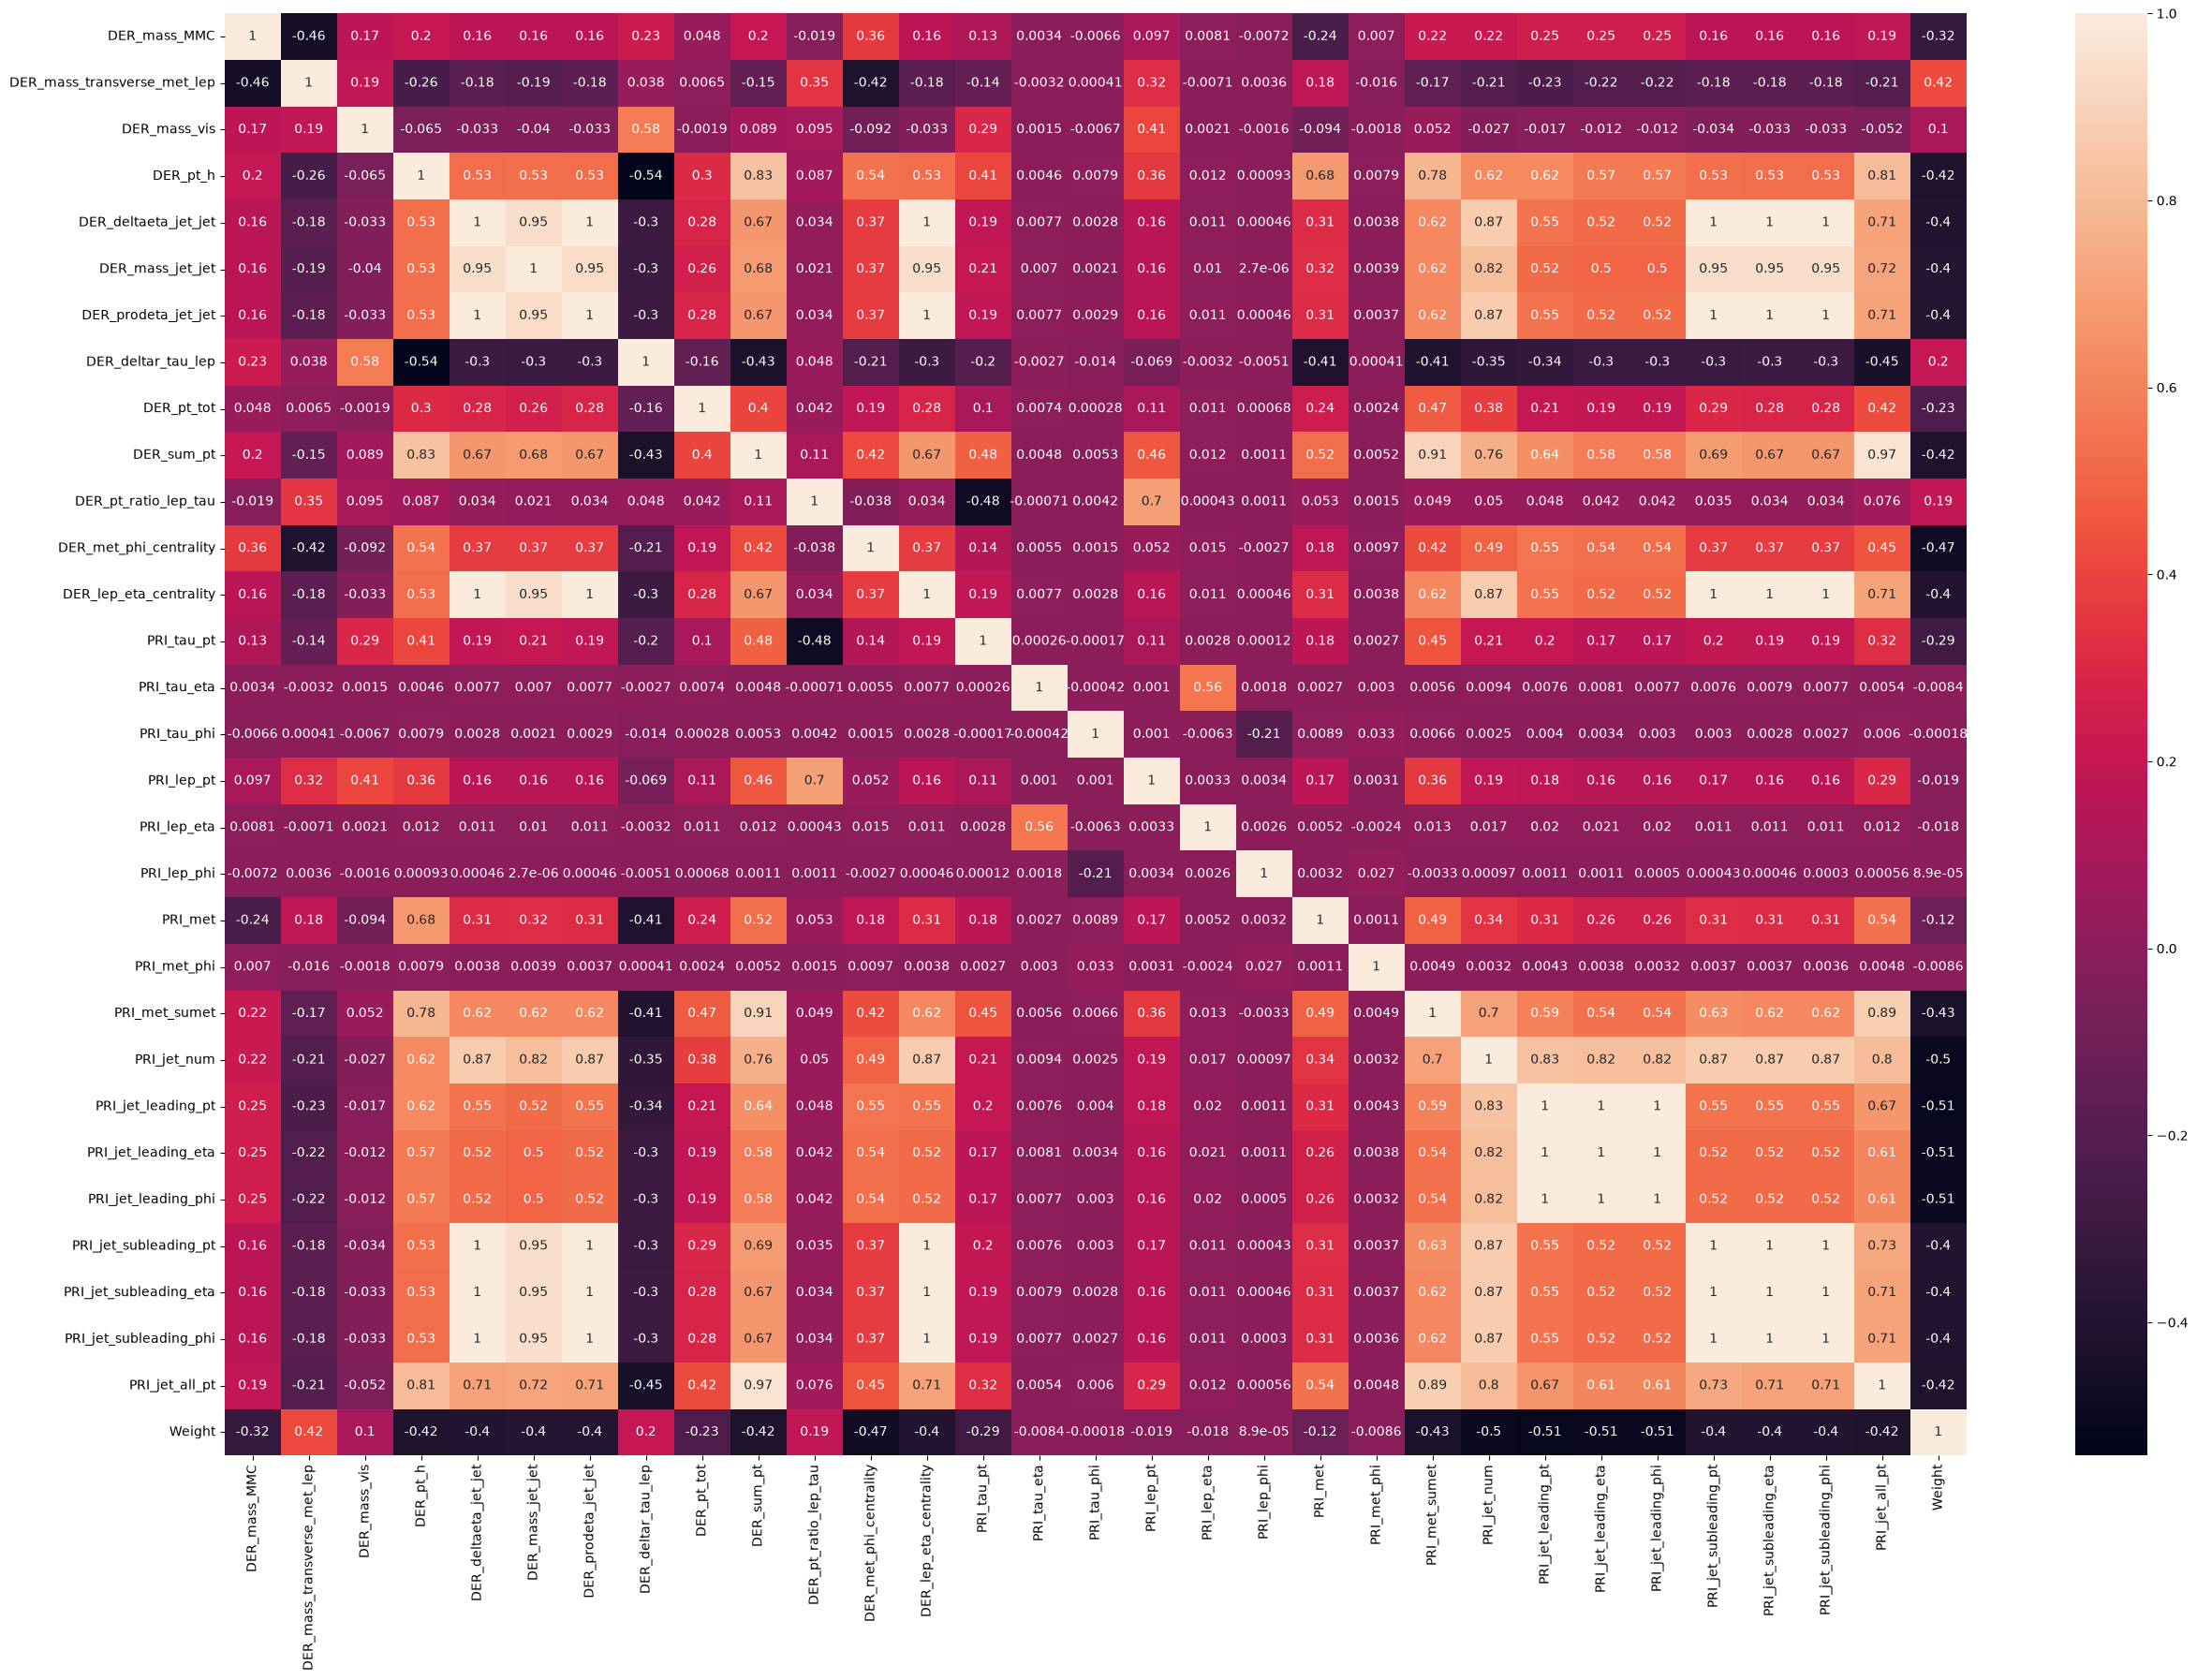

In [6]:
#CORRELATION MATRIX
plt.figure(figsize=(30, 20)) # Adjust the figure size for better visibility
sns.heatmap(exp_df[features].corr(), annot=True)
plt.show()

* **PRI_met_phi**, **PRI_tau_phi**, and **PRI_lep_phi** has very little correlation with other parameters.

* **PRI_lep_eta**, and **PRI_tau_eta** only has any real correlation with eachother. 

### Models to train:
* Random forest
* XGBoost

In [7]:
# INITIAL TEST OF RANDOM FOREST AND XGBOOST
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV
import xgboost as xgb
from feature_selection import add_features
rand_seed = 42

cross_val = StratifiedKFold(n_splits = 5,
                            shuffle = True,
                            random_state = rand_seed
                           )

param_grid = {"n_estimators": [100, 200, 400, 800],
                "max_depth": [2, 3, 4, 6]}

rand_forest = RandomForestClassifier(random_state = rand_seed,
                                     n_jobs= -1,
                                     verbose = True
                                    )

xgb_model = xgb.XGBClassifier(n_jobs = -1, 
                             tree_method = "hist",
                            )

grid_search_forest = GridSearchCV(rand_forest,
                           param_grid,
                           cv = cross_val,
                           scoring = 'precision',
                           verbose = True,
                          )

grid_search_xgb = GridSearchCV(xgb_model,
                           param_grid,
                           cv = cross_val,
                           scoring = 'precision',
                           verbose = True,
                          )

training_features = [f for f in features if f not in ["Weight","PRI_met_phi", "PRI_tau_phi", "PRI_lep_phi", "PRI_lep_eta", "PRI_tau_eta"]]
all_training_features = [f for f in features if f not in ["Weight"]]

# Does not improve the model lol.
new_df = add_features(exp_df)
X = new_df[[c for c in new_df.columns if c not in ["Weight", "Label"]]].to_numpy()
y = new_df["Label"].to_numpy()

/home/olle/teknisk-fysik/machine-learning-in-physics/final-project/feature_selection.py:29: RuntimeWarning: overflow encountered in sinh
  comp = p * np.sinh(eta)


In [8]:
grid_search_forest.fit(X,y)

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 16 concurrent workers.


Fitting 5 folds for each of 16 candidates, totalling 80 fits


[Parallel(n_jobs=-1)]: Done  18 tasks      | elapsed:    0.5s
[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed:    1.7s finished
[Parallel(n_jobs=16)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=16)]: Done  18 tasks      | elapsed:    0.0s
[Parallel(n_jobs=16)]: Done 100 out of 100 | elapsed:    0.1s finished
[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=-1)]: Done  18 tasks      | elapsed:    0.5s
[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed:    1.9s finished
[Parallel(n_jobs=16)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=16)]: Done  18 tasks      | elapsed:    0.0s
[Parallel(n_jobs=16)]: Done 100 out of 100 | elapsed:    0.1s finished
[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=-1)]: Done  18 tasks      | elapsed:    0.5s
[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed:    1.7s finished
[Parall

KeyboardInterrupt: 

In [ ]:
print("Selected params:")
print(grid_search_forest.best_params_)

print("\nCross val score:")
print(f"{grid_search_forest.best_score_:.3f}")

Selected params:
{'max_depth': 2, 'n_estimators': 200}

Cross val score:
0.829


In [9]:
grid_search_xgb.fit(X,y)

Fitting 5 folds for each of 16 candidates, totalling 80 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [2, 3, ...], 'n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'precision'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",True
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_pl

In [10]:
print("Selected params:")
print(grid_search_xgb.best_params_)

print("\nCross val score:")
print(f"{grid_search_xgb.best_score_:.3f}")

Selected params:
{'max_depth': 4, 'n_estimators': 200}

Cross val score:
0.787
